In [ ]:
# Mount Google Drive (recommended to store dataset)
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import zipfile
with zipfile.ZipFile('/content/drive/MyDrive/Colab Notebooks/archive.zip', 'r') as zip_ref:
    zip_ref.extractall('/content/brain_tumor')

In [ ]:
# Install if needed
!pip install tensorflow opencv-python matplotlib seaborn scikit-learn

# Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
import os

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import VGG16, ResNet50, EfficientNetB0
from sklearn.metrics import classification_report, confusion_matrix

In [ ]:
# Check folder structure
dataset_path = '/content/brain_tumor'
classes = os.listdir(dataset_path)
print("Classes:", classes)

# Count images per class
for cls in classes:
    count = len(os.listdir(os.path.join(dataset_path, cls)))
    print(f"{cls}: {count} images")

import os

dataset_path = '/content/brain_tumor'

print(" Top-level folders/files:")
for item in os.listdir(dataset_path):
    item_path = os.path.join(dataset_path, item)
    if os.path.isdir(item_path):
        files = os.listdir(item_path)
        print(f" {item}/ → {len(files)} files → First few: {files[:5]}")
    else:
        print(f"   {item}  ← (not a folder!)")

Classes: ['Training', 'Testing']
Training: 4 images
Testing: 4 images
📁 Top-level folders/files:
  📂 Training/ → 4 files → First few: ['meningioma', 'notumor', 'glioma', 'pituitary']
  📂 Testing/ → 4 files → First few: ['meningioma', 'notumor', 'glioma', 'pituitary']


✅ Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']

📊 Dataset Summary:
  glioma          → Train: 1400  |  Test:  400
  meningioma      → Train: 1400  |  Test:  400
  notumor         → Train: 1400  |  Test:  400
  pituitary       → Train: 1400  |  Test:  400


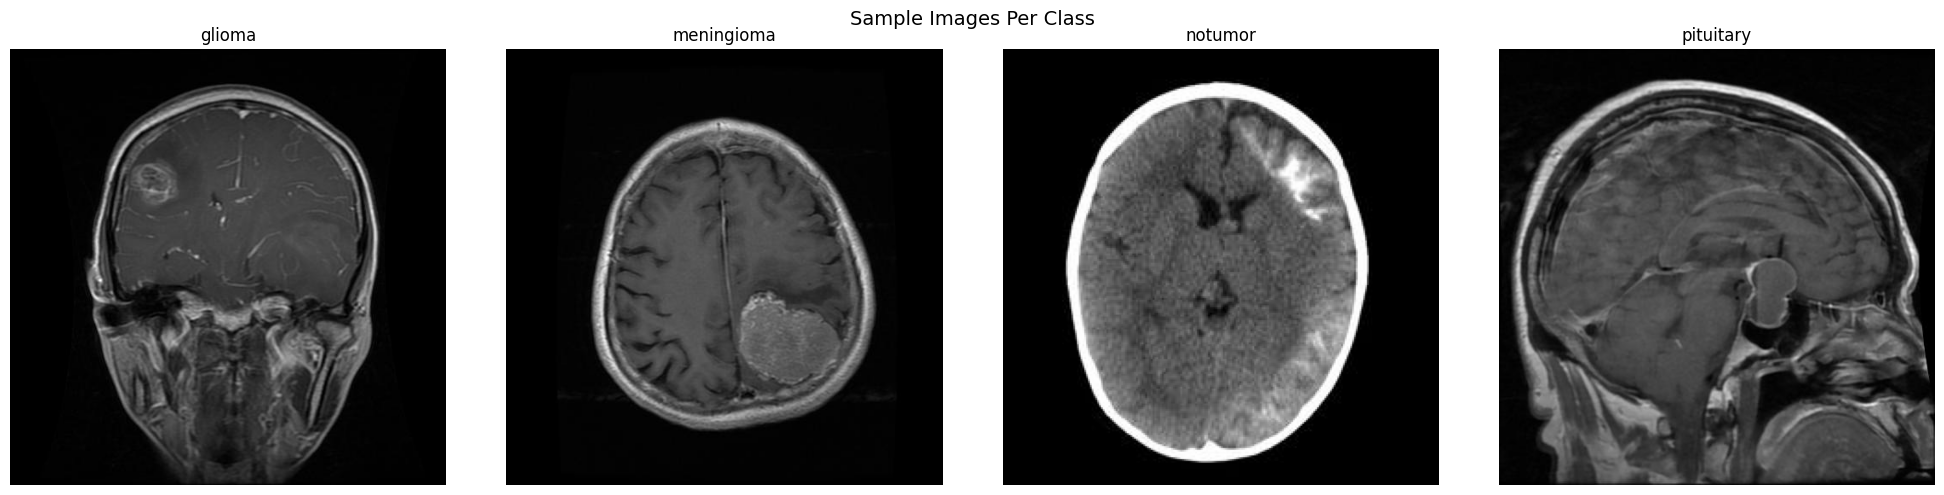

In [ ]:
import cv2
import matplotlib.pyplot as plt
import os

#  CORRECT PATHS
dataset_path = '/content/brain_tumor'
train_path   = os.path.join(dataset_path, 'Training')
test_path    = os.path.join(dataset_path, 'Testing')

#  Classes are INSIDE Training folder
classes = sorted(os.listdir(train_path))
print(" Classes:", classes)

IMG_EXTS = ('.jpg', '.jpeg', '.png', '.bmp')

#  Count images properly
print("\n📊 Dataset Summary:")
for cls in classes:
    tr_path = os.path.join(train_path, cls)
    te_path = os.path.join(test_path, cls)
    tr_count = len([f for f in os.listdir(tr_path) if f.lower().endswith(IMG_EXTS)])
    te_count = len([f for f in os.listdir(te_path) if f.lower().endswith(IMG_EXTS)])
    print(f"  {cls:15s} → Train: {tr_count:4d}  |  Test: {te_count:4d}")

#  Visualize one image per class
fig, axes = plt.subplots(1, len(classes), figsize=(5 * len(classes), 5))

for i, cls in enumerate(classes):
    cls_path = os.path.join(train_path, cls)  # ← Training/glioma/, etc.
    imgs = [f for f in os.listdir(cls_path) if f.lower().endswith(IMG_EXTS)]

    if not imgs:
        axes[i].set_title(f"{cls}\n(empty)")
        axes[i].axis('off')
        continue

    img = cv2.imread(os.path.join(cls_path, imgs[0]))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    axes[i].imshow(img)
    axes[i].set_title(cls, fontsize=12)
    axes[i].axis('off')

plt.suptitle("Sample Images Per Class", fontsize=14)
plt.tight_layout()
plt.show()

In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

IMG_SIZE   = 224
BATCH_SIZE = 32

# Training augmentation
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True
)

# Test — only rescale, no augmentation
test_datagen = ImageDataGenerator(rescale=1./255)

#  Use train_path and test_path directly (no validation_split needed!)
train_generator = train_datagen.flow_from_directory(
    train_path,                        # ← /content/brain_tumor/Training
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=True
)

test_generator = test_datagen.flow_from_directory(
    test_path,                         # ← /content/brain_tumor/Testing
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False                      # ← False for correct evaluation
)

print("\n Class Indices:", train_generator.class_indices)
print(f" Train batches: {len(train_generator)}")
print(f" Test  batches: {len(test_generator)}")

Found 5600 images belonging to 4 classes.
Found 1600 images belonging to 4 classes.

✅ Class Indices: {'glioma': 0, 'meningioma': 1, 'notumor': 2, 'pituitary': 3}
✅ Train batches: 175
✅ Test  batches: 50


In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import VGG16

NUM_CLASSES = len(classes)  # = 4

base_model = VGG16(weights='imagenet', include_top=False,
                   input_shape=(IMG_SIZE, IMG_SIZE, 3))
base_model.trainable = False

model = keras.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(512, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(NUM_CLASSES, activation='softmax')
])

model.summary()

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │       262,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,109,700 (57.64 MB)

 Trainable params: 395,012 (1.51 MB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import VGG16
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import numpy as np

# ─────────────────────────────────────────
# STEP 1 — PATHS & SETTINGS
# ─────────────────────────────────────────
dataset_path = '/content/brain_tumor'
train_path   = os.path.join(dataset_path, 'Training')
test_path    = os.path.join(dataset_path, 'Testing')

IMG_SIZE    = 224
BATCH_SIZE  = 32
NUM_CLASSES = 4

# ─────────────────────────────────────────
# STEP 2 — DATA GENERATORS
# ─────────────────────────────────────────
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True
)
test_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_directory(
    train_path,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=True
)

test_generator = test_datagen.flow_from_directory(
    test_path,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

print(" Class Indices:", train_generator.class_indices)
print(f" Train samples : {train_generator.samples}")
print(f" Test  samples : {test_generator.samples}")

# ─────────────────────────────────────────
# STEP 3 — BUILD MODEL
# ─────────────────────────────────────────
base_model = VGG16(
    weights='imagenet',
    include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)
base_model.trainable = False  # Freeze pretrained layers

model = keras.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(512, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(NUM_CLASSES, activation='softmax')
])

print("\n Model built successfully!")
model.summary()

# ─────────────────────────────────────────
# STEP 4 — COMPILE
# ─────────────────────────────────────────
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)
print(" Model compiled!")

# ─────────────────────────────────────────
# STEP 5 — CALLBACKS
# ─────────────────────────────────────────
callbacks = [
    keras.callbacks.EarlyStopping(
        monitor='val_accuracy',
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.2,
        patience=3,
        verbose=1
    ),
    keras.callbacks.ModelCheckpoint(
        'best_model.h5',
        monitor='val_accuracy',
        save_best_only=True,
        verbose=1
    )
]

# ─────────────────────────────────────────
# STEP 6 — TRAIN
# ─────────────────────────────────────────
print("\n Starting Training...\n")
history = model.fit(
    train_generator,
    epochs=30,
    validation_data=test_generator,
    callbacks=callbacks
)

print("\n Training Complete!")

Found 5600 images belonging to 4 classes.
Found 1600 images belonging to 4 classes.
✅ Class Indices: {'glioma': 0, 'meningioma': 1, 'notumor': 2, 'pituitary': 3}
✅ Train samples : 5600
✅ Test  samples : 1600

✅ Model built successfully!


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 512)            │       262,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,109,700 (57.64 MB)

 Trainable params: 395,012 (1.51 MB)

 Non-trainable params: 14,714,688 (56.13 MB)

... (5 outputs left out)


Epoch 5: finished saving model to best_model.h5
175/175 ━━━━━━━━━━━━━━━━━━━━ 111s 632ms/step - accuracy: 0.7511 - loss: 0.6553 - val_accuracy: 0.7500 - val_loss: 0.8100 - learning_rate: 1.0000e-04
Epoch 6/15
175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 560ms/step - accuracy: 0.7447 - loss: 0.6368
Epoch 6: val_accuracy did not improve from 0.75000
175/175 ━━━━━━━━━━━━━━━━━━━━ 109s 623ms/step - accuracy: 0.7563 - loss: 0.6225 - val_accuracy: 0.7406 - val_loss: 0.7827 - learning_rate: 1.0000e-04
Epoch 7/15
175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 562ms/step - accuracy: 0.7754 - loss: 0.5825
Epoch 7: val_accuracy did not improve from 0.75000
175/175 ━━━━━━━━━━━━━━━━━━━━ 110s 626ms/step - accuracy: 0.7745 - loss: 0.5881 - val_accuracy: 0.7394 - val_loss: 0.8139 - learning_rate: 1.0000e-04
Epoch 8/15
175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 536ms/step - accuracy: 0.7876 - loss: 0.5727
Epoch 8: val_accuracy improved from 0.75000 to 0.75813, saving model to best_model.h5



Epoch 8: finished saving model to best_model.h5
175/175 ━━━━━━━━━━━━━━━━━━━━ 106s 600ms/step - accuracy: 0.7904 - loss: 0.5620 - val_accuracy: 0.7581 - val_loss: 0.7733 - learning_rate: 1.0000e-04
Epoch 9/15
175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 508ms/step - accuracy: 0.7992 - loss: 0.5302
Epoch 9: val_accuracy did not improve from 0.75813
175/175 ━━━━━━━━━━━━━━━━━━━━ 101s 572ms/step - accuracy: 0.7995 - loss: 0.5338 - val_accuracy: 0.7550 - val_loss: 0.7981 - learning_rate: 1.0000e-04
Epoch 10/15
175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 496ms/step - accuracy: 0.8070 - loss: 0.5174
Epoch 10: val_accuracy did not improve from 0.75813
175/175 ━━━━━━━━━━━━━━━━━━━━ 98s 561ms/step - accuracy: 0.8052 - loss: 0.5209 - val_accuracy: 0.7556 - val_loss: 0.8029 - learning_rate: 1.0000e-04
Epoch 11/15
175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 493ms/step - accuracy: 0.8236 - loss: 0.4822
Epoch 11: val_accuracy improved from 0.75813 to 0.76812, saving model to best_model.h5



Epoch 11: finished saving model to best_model.h5
175/175 ━━━━━━━━━━━━━━━━━━━━ 98s 559ms/step - accuracy: 0.8109 - loss: 0.5023 - val_accuracy: 0.7681 - val_loss: 0.7474 - learning_rate: 1.0000e-04
Epoch 12/15
175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 503ms/step - accuracy: 0.8097 - loss: 0.5121
Epoch 12: val_accuracy did not improve from 0.76812
175/175 ━━━━━━━━━━━━━━━━━━━━ 99s 568ms/step - accuracy: 0.8104 - loss: 0.5000 - val_accuracy: 0.7569 - val_loss: 0.7770 - learning_rate: 1.0000e-04
Epoch 13/15
175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 508ms/step - accuracy: 0.8180 - loss: 0.4945
Epoch 13: val_accuracy improved from 0.76812 to 0.78375, saving model to best_model.h5



Epoch 13: finished saving model to best_model.h5
175/175 ━━━━━━━━━━━━━━━━━━━━ 100s 573ms/step - accuracy: 0.8245 - loss: 0.4731 - val_accuracy: 0.7837 - val_loss: 0.7043 - learning_rate: 1.0000e-04
Epoch 14/15
175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 504ms/step - accuracy: 0.8146 - loss: 0.4854
Epoch 14: val_accuracy did not improve from 0.78375
175/175 ━━━━━━━━━━━━━━━━━━━━ 100s 569ms/step - accuracy: 0.8291 - loss: 0.4670 - val_accuracy: 0.7725 - val_loss: 0.7345 - learning_rate: 1.0000e-04
Epoch 15/15
175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 503ms/step - accuracy: 0.8308 - loss: 0.4682
Epoch 15: val_accuracy did not improve from 0.78375
175/175 ━━━━━━━━━━━━━━━━━━━━ 142s 567ms/step - accuracy: 0.8323 - loss: 0.4555 - val_accuracy: 0.7619 - val_loss: 0.7347 - learning_rate: 1.0000e-04
Restoring model weights from the end of the best epoch: 13.

🎉 Training Complete!


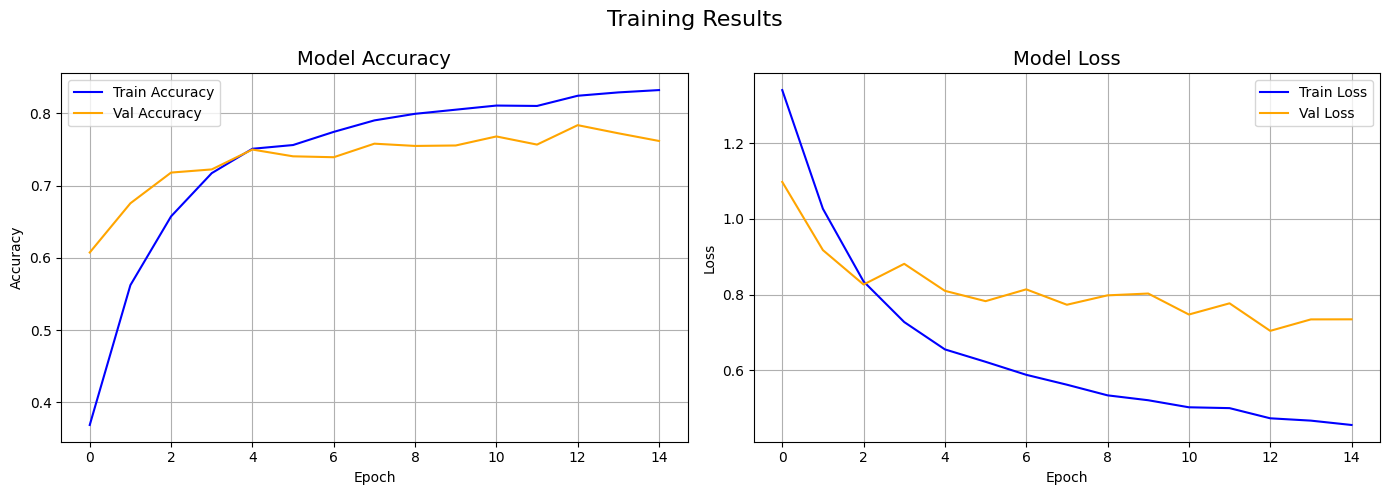

In [26]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy
axes[0].plot(history.history['accuracy'],     label='Train Accuracy', color='blue')
axes[0].plot(history.history['val_accuracy'], label='Val Accuracy',   color='orange')
axes[0].set_title('Model Accuracy', fontsize=14)
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(True)

# Loss
axes[1].plot(history.history['loss'],     label='Train Loss', color='blue')
axes[1].plot(history.history['val_loss'], label='Val Loss',   color='orange')
axes[1].set_title('Model Loss', fontsize=14)
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(True)

plt.suptitle('Training Results', fontsize=16)
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import classification_report
import numpy as np

# Predict on test set
test_generator.reset()
y_pred       = model.predict(test_generator, verbose=1)
y_pred_class = np.argmax(y_pred, axis=1)
y_true       = test_generator.classes

class_names = list(train_generator.class_indices.keys())

print("\n Classification Report:")
print("=" * 55)
print(classification_report(y_true, y_pred_class, target_names=class_names))

50/50 ━━━━━━━━━━━━━━━━━━━━ 13s 211ms/step

📋 Classification Report:
              precision    recall  f1-score   support

      glioma       0.85      0.60      0.70       400
  meningioma       0.76      0.57      0.65       400
     notumor       0.80      0.99      0.88       400
   pituitary       0.74      0.98      0.85       400

    accuracy                           0.78      1600
   macro avg       0.79      0.78      0.77      1600
weighted avg       0.79      0.78      0.77      1600



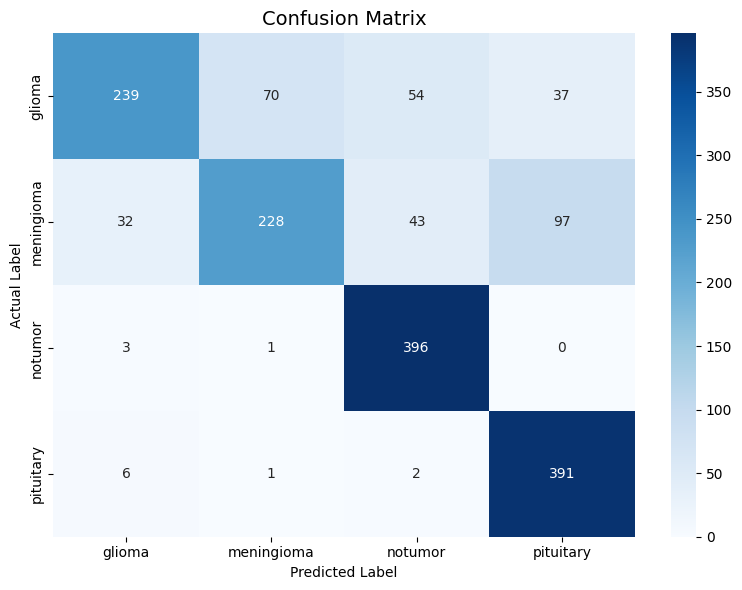

In [28]:
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_true, y_pred_class)

plt.figure(figsize=(8, 6))
sns.heatmap(cm,
            annot=True,
            fmt='d',
            cmap='Blues',
            xticklabels=class_names,
            yticklabels=class_names)
plt.title('Confusion Matrix', fontsize=14)
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.tight_layout()
plt.show()

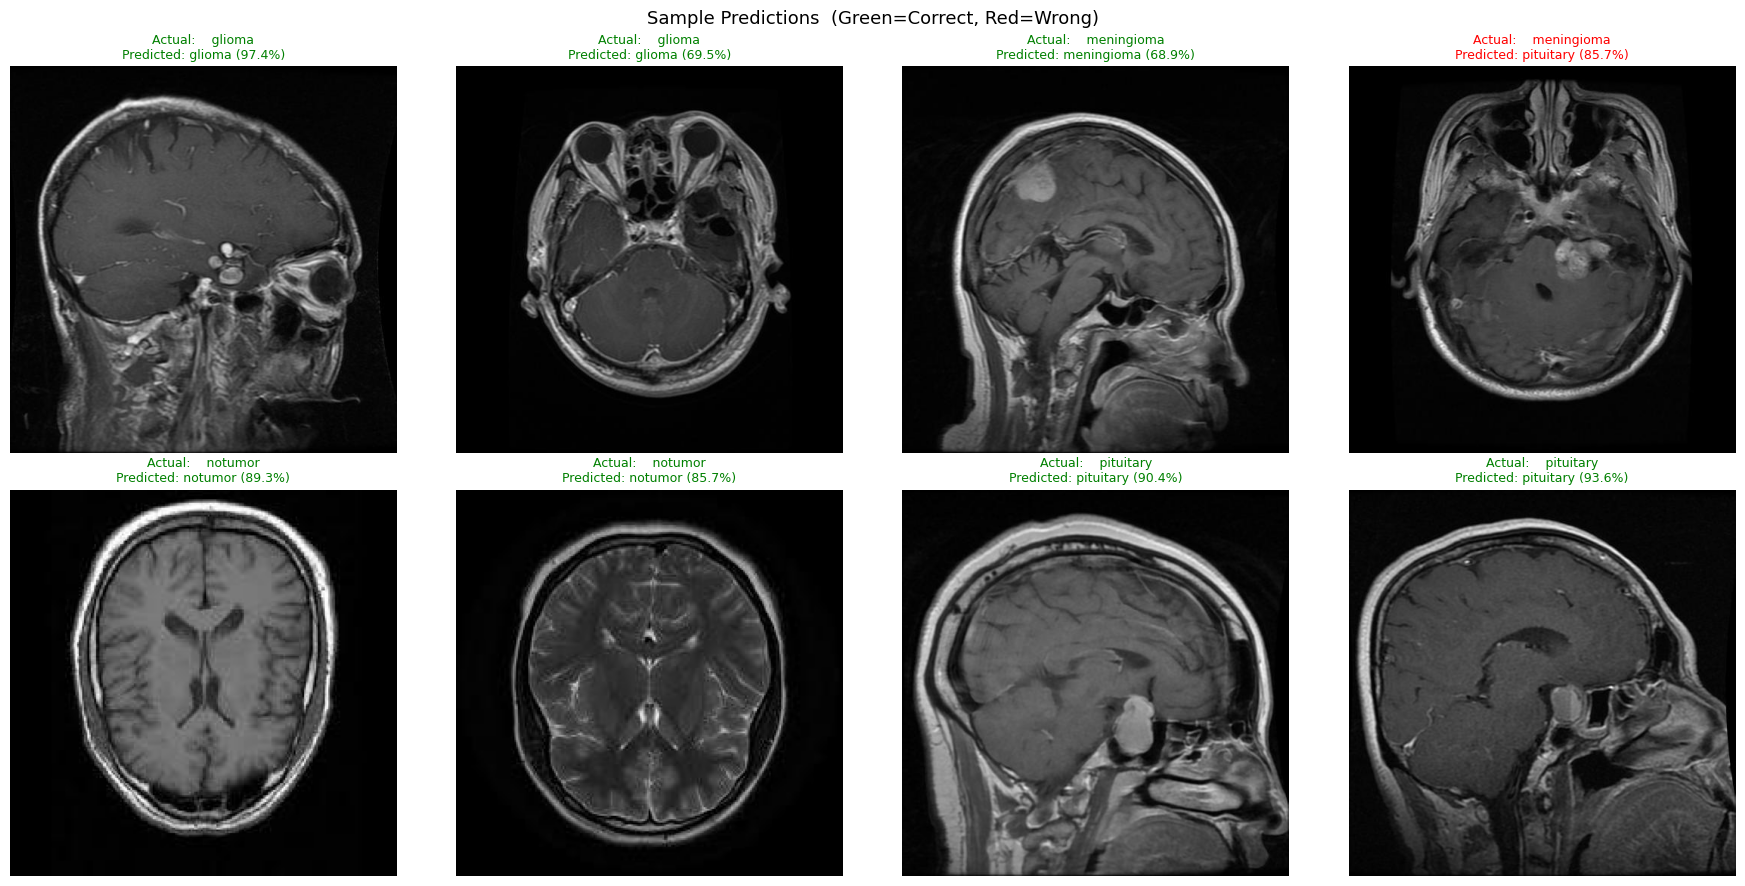

In [29]:
import cv2

def predict_and_show(test_path, model, class_names, num_images=8):
    IMG_EXTS = ('.jpg', '.jpeg', '.png', '.bmp')
    all_images = []

    for cls in class_names:
        cls_path = os.path.join(test_path, cls)
        imgs = [os.path.join(cls_path, f)
                for f in os.listdir(cls_path)
                if f.lower().endswith(IMG_EXTS)]
        all_images.extend([(p, cls) for p in imgs[:2]])  # 2 per class

    fig, axes = plt.subplots(2, 4, figsize=(18, 9))
    axes = axes.flatten()

    for i, (img_path, true_label) in enumerate(all_images[:num_images]):
        img_bgr  = cv2.imread(img_path)
        img_rgb  = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
        img_res  = cv2.resize(img_rgb, (224, 224))
        img_norm = img_res / 255.0
        img_inp  = np.expand_dims(img_norm, axis=0)

        pred       = model.predict(img_inp, verbose=0)
        pred_label = class_names[np.argmax(pred)]
        confidence = np.max(pred) * 100

        # Green = correct, Red = wrong
        color = 'green' if pred_label == true_label else 'red'

        axes[i].imshow(img_rgb)
        axes[i].set_title(
            f"Actual:    {true_label}\nPredicted: {pred_label} ({confidence:.1f}%)",
            fontsize=9, color=color
        )
        axes[i].axis('off')

    plt.suptitle('Sample Predictions  (Green=Correct, Red=Wrong)', fontsize=13)
    plt.tight_layout()
    plt.show()

predict_and_show(test_path, model, class_names)

In [ ]:
# ─────────────────────────────────────────
# SAVE MODEL — using modern .keras format
# ─────────────────────────────────────────

# Save locally in Colab
model.save('/content/brain_tumor_model.keras')
print(" Model saved locally!")

# Save to Google Drive (won't lose it if Colab disconnects)
import shutil
shutil.copy('/content/brain_tumor_model.keras',
            '/content/drive/MyDrive/brain_tumor_model.keras')
print(" Model saved to Google Drive!")

# ─────────────────────────────────────────
# PRINT FINAL RESULTS
# ─────────────────────────────────────────
final_train_acc = max(history.history['accuracy'])
final_val_acc   = max(history.history['val_accuracy'])

print(f"\n{'='*40}")
print(f" Best Train Accuracy : {final_train_acc*100:.2f}%")
print(f" Best Val   Accuracy : {final_val_acc*100:.2f}%")
print(f"{'='*40}")

✅ Model saved locally!
✅ Model saved to Google Drive!

🏆 Best Train Accuracy : 83.23%
🏆 Best Val   Accuracy : 78.37%


In [ ]:
# Unfreeze last 4 layers of VGG16
base_model.trainable = True
for layer in base_model.layers[:-8]:  # freeze all except last 8
    layer.trainable = False

# Check trainable layers
print(" Trainable layers:")
for layer in base_model.layers:
    if layer.trainable:
        print(f"    {layer.name}")

# Recompile with VERY low learning rate
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),  # 10x smaller
    loss='categorical_crossentropy',
    metrics=['accuracy']
)
print("\n Model recompiled for fine-tuning!")

🔓 Trainable layers:
   ✅ block4_conv1
   ✅ block4_conv2
   ✅ block4_conv3
   ✅ block4_pool
   ✅ block5_conv1
   ✅ block5_conv2
   ✅ block5_conv3
   ✅ block5_pool

✅ Model recompiled for fine-tuning!


In [ ]:
callbacks_finetune = [
    keras.callbacks.EarlyStopping(
        monitor='val_accuracy',
        patience=7,
        restore_best_weights=True,
        verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.2,
        patience=3,
        min_lr=1e-7,
        verbose=1
    ),
    keras.callbacks.ModelCheckpoint(
        '/content/drive/MyDrive/best_finetuned_model.keras',
        monitor='val_accuracy',
        save_best_only=True,
        verbose=1
    )
]

print(" Starting Fine-Tuning...\n")
history_fine = model.fit(
    train_generator,
    epochs=30,          # will stop early if no improvement
    validation_data=test_generator,
    callbacks=callbacks_finetune
)

print("\n Fine-Tuning Complete!")

🚀 Starting Fine-Tuning...

Epoch 1/30
175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 581ms/step - accuracy: 0.8307 - loss: 0.4600
Epoch 1: val_accuracy improved from None to 0.81375, saving model to /content/drive/MyDrive/best_finetuned_model.keras

Epoch 1: finished saving model to /content/drive/MyDrive/best_finetuned_model.keras
175/175 ━━━━━━━━━━━━━━━━━━━━ 132s 647ms/step - accuracy: 0.8507 - loss: 0.4093 - val_accuracy: 0.8138 - val_loss: 0.6814 - learning_rate: 1.0000e-05
Epoch 2/30
175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 590ms/step - accuracy: 0.8809 - loss: 0.3277
Epoch 2: val_accuracy improved from 0.81375 to 0.81625, saving model to /content/drive/MyDrive/best_finetuned_model.keras

Epoch 2: finished saving model to /content/drive/MyDrive/best_finetuned_model.keras
175/175 ━━━━━━━━━━━━━━━━━━━━ 114s 649ms/step - accuracy: 0.8880 - loss: 0.3053 - val_accuracy: 0.8163 - val_loss: 0.6099 - learning_rate: 1.0000e-05
Epoch 3/30
175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 583ms/step - accuracy: 0.9171 - loss: 0.2372


In [ ]:
# Rebuild generators with stronger augmentation
train_datagen_v2 = ImageDataGenerator(
    rescale=1./255,
    rotation_range=30,          # was 20
    width_shift_range=0.3,      # was 0.2
    height_shift_range=0.3,     # was 0.2
    shear_range=0.3,
    zoom_range=0.3,
    horizontal_flip=True,
    vertical_flip=True,         # ← new
    brightness_range=[0.8, 1.2],# ← new
    fill_mode='nearest'
)

train_generator_v2 = train_datagen_v2.flow_from_directory(
    train_path,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=32,
    class_mode='categorical',
    shuffle=True
)

print(" Stronger augmentation applied!")

Found 5600 images belonging to 4 classes.
✅ Stronger augmentation applied!


In [ ]:
from tensorflow.keras.applications import EfficientNetB0

# ─── Build stronger model ───
base_eff = EfficientNetB0(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3)
)
base_eff.trainable = False

model_eff = keras.Sequential([
    base_eff,
    layers.GlobalAveragePooling2D(),
    layers.BatchNormalization(),      # ← helps stability
    layers.Dense(512, activation='relu'),
    layers.Dropout(0.4),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(NUM_CLASSES, activation='softmax')
])

model_eff.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print(" EfficientNetB0 model built!")
model_eff.summary()

# ─── Train EfficientNet ───
callbacks_eff = [
    keras.callbacks.EarlyStopping(patience=7, restore_best_weights=True, verbose=1),
    keras.callbacks.ReduceLROnPlateau(factor=0.2, patience=3, verbose=1),
    keras.callbacks.ModelCheckpoint(
        '/content/drive/MyDrive/best_efficientnet_model.keras',
        save_best_only=True, verbose=1
    )
]

print("\n Training EfficientNetB0...\n")
history_eff = model_eff.fit(
    train_generator_v2,
    epochs=30,
    validation_data=test_generator,
    callbacks=callbacks_eff
)
print("\n EfficientNet Training Complete!")

✅ EfficientNetB0 model built!


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_4      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 512)            │       655,872 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,842,919 (18.47 MB)

 Trainable params: 790,788 (3.02 MB)

 Non-trainable params: 4,052,131 (15.46 MB)


🚀 Training EfficientNetB0...

Epoch 1/30
175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 509ms/step - accuracy: 0.2638 - loss: 1.4818
Epoch 1: val_loss improved from None to 1.38337, saving model to /content/drive/MyDrive/best_efficientnet_model.keras

Epoch 1: finished saving model to /content/drive/MyDrive/best_efficientnet_model.keras
175/175 ━━━━━━━━━━━━━━━━━━━━ 125s 579ms/step - accuracy: 0.2768 - loss: 1.4527 - val_accuracy: 0.2575 - val_loss: 1.3834 - learning_rate: 1.0000e-04
Epoch 2/30
175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 516ms/step - accuracy: 0.2792 - loss: 1.4308
Epoch 2: val_loss improved from 1.38337 to 1.37161, saving model to /content/drive/MyDrive/best_efficientnet_model.keras

Epoch 2: finished saving model to /content/drive/MyDrive/best_efficientnet_model.keras
175/175 ━━━━━━━━━━━━━━━━━━━━ 95s 539ms/step - accuracy: 0.2845 - loss: 1.4240 - val_accuracy: 0.3850 - val_loss: 1.3716 - learning_rate: 1.0000e-04
Epoch 3/30
175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 504ms/step - accuracy: 0.2963 - loss: 

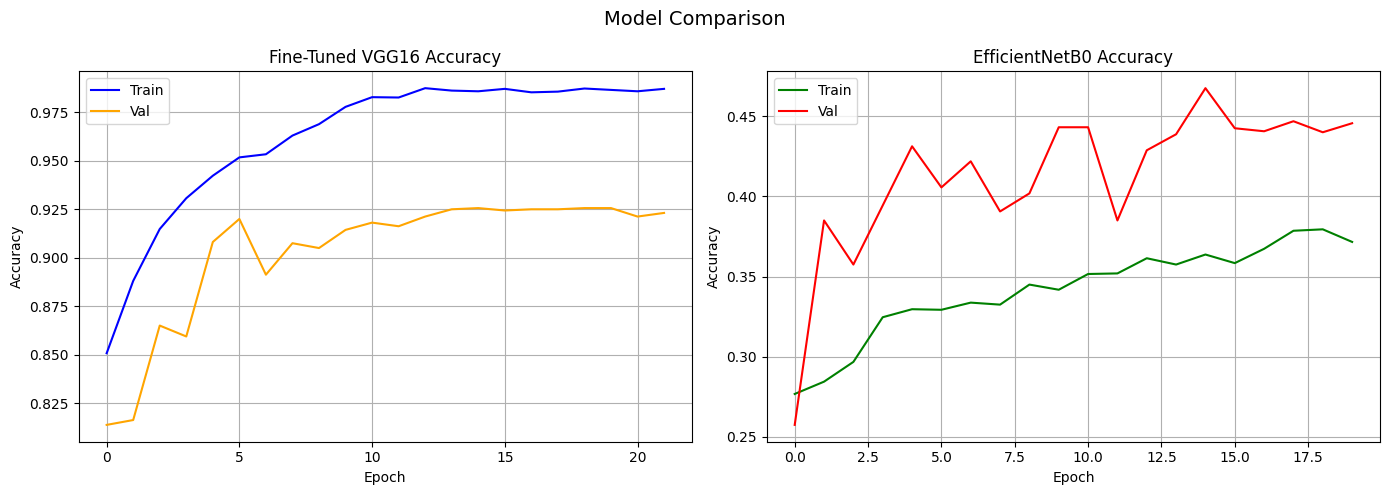


📊 Fine-Tuned VGG16    : 92.56%
📊 EfficientNetB0      : 46.75%
🏆 Best Model          : Fine-Tuned VGG16


In [ ]:
plt.figure(figsize=(14, 5))

# Fine-tuned VGG16
plt.subplot(1, 2, 1)
plt.plot(history_fine.history['accuracy'],     label='Train', color='blue')
plt.plot(history_fine.history['val_accuracy'], label='Val',   color='orange')
plt.title('Fine-Tuned VGG16 Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# EfficientNet
plt.subplot(1, 2, 2)
plt.plot(history_eff.history['accuracy'],     label='Train', color='green')
plt.plot(history_eff.history['val_accuracy'], label='Val',   color='red')
plt.title('EfficientNetB0 Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.suptitle('Model Comparison', fontsize=14)
plt.tight_layout()
plt.show()

# Print comparison
vgg_best = max(history_fine.history['val_accuracy']) * 100
eff_best = max(history_eff.history['val_accuracy'])  * 100

print(f"\n{'='*40}")
print(f" Fine-Tuned VGG16    : {vgg_best:.2f}%")
print(f" EfficientNetB0      : {eff_best:.2f}%")
print(f"{'='*40}")
print(f" Best Model          : {'EfficientNetB0' if eff_best > vgg_best else 'Fine-Tuned VGG16'}")
print(f"{'='*40}")